# 🌱 Greenhouse Investigation, Part 2: Testing and Interpreting

In Part 1, we explored bean heights and compared density treatments using one average height per pot.

Now we’ll evaluate the evidence for differences among treatments.

We’ll choose a statistical test, consider its assumptions, interpret the results, and prepare graphs and tables for communicating our findings.

## 💻 Start Here

Run the setup cell below, even if you already completed Part 1.

It loads the dataset and calculates one average bean height per pot. You do not need to rerun Part 1.

In [2]:
# Load our tools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("greenhouse_density_data.csv")

# Select bean height measurements
bean_heights = df[
    (df["Species"] == "Bean") &
    (df["Metric"] == "Height")
]

# Calculate one mean height per pot
bean_pot_heights = (
    bean_heights
    .groupby(["Group", "Density", "Pot ID"], as_index=False)
    .agg(
        Mean_height_cm=("Value", "mean"),
        Plants_measured=("Value", "count")
    )
)

print("🌱 Ready! Bean heights are summarized by pot.")
print()

for density in ["Low", "Med", "High"]:
    pot_means = bean_pot_heights.loc[
        bean_pot_heights["Density"] == density,
        "Mean_height_cm"
    ]

    print(
        f"{density} density: {len(pot_means)} pots, "
        f"average height = {pot_means.mean():.2f} cm"
    )

🌱 Ready! Bean heights are summarized by pot.

Low density: 8 pots, average height = 44.09 cm
Med density: 5 pots, average height = 35.23 cm
High density: 7 pots, average height = 35.26 cm


# 🌱 Experiment 4: Choosing a Statistical Test

In Part 1, we explored bean heights and calculated one average height per pot.

We observed differences among density treatments. But differences in sample averages can occur even when a treatment has no effect.

How can we evaluate the evidence?

## 🤔 Choose a Test

Our question is:

**Does average bean height differ among density treatments?**

Consider what we have:

- A **numerical response**: mean plant height per pot.
- One experimental treatment factor: **density**.
- Three treatment levels: **Low, Med, and High**.
- Separate pots providing treatment replicates.

A **one-way analysis of variance**, or **one-way ANOVA**, is a starting point for comparing means across levels of one factor.

“One-way” refers to the number of factors being examined, not the number of treatment levels.

## ⚖️ What Does ANOVA Compare?

ANOVA compares variation **among treatment means** with variation **among pots within treatments**.

Differences among treatment means provide stronger evidence when they are large relative to the variation within treatments.

## 🤔 Think

Two experiments have exactly the same three treatment means.

- In Experiment A, the pot heights within each treatment are very similar.
- In Experiment B, the pot heights within each treatment vary widely.

Which experiment would provide stronger evidence of a treatment effect? Explain your reasoning.

## 🧩 Consider the Experimental Design

Our dataset combines measurements collected by two student groups.

Differences between groups could contribute to the variation we observe. We retained the **Group** column so this information can be considered when choosing the final analysis.

Choosing a test requires understanding both the measurements and how the experiment was conducted.

## 🔎 Check the Variation Within Treatments

Statistical tests make assumptions about the data. Checking these helps us decide whether a test is appropriate.

For ordinary one-way ANOVA, we consider:

- **Independence:** each observation used in the test should come from a separate experimental unit. We use one mean per pot because plants sharing a pot are not independent replicates.
- **Similar variation:** the amount of variation among pot means should be reasonably similar across treatments.
- **Approximate normality:** deviations of pot means from their treatment average should roughly follow a bell-shaped pattern, with small deviations more common than large ones.

The treatments do **not** need to have the same mean—that is what we’re investigating! Real biological data also do not need to form a perfect bell shape.

We’ll examine variation among treatments together. Your instructor will guide the remaining assumption checks and the choice of analysis.

## 📊 Revisit the Pot Means

Each point below represents one pot’s average bean height.

The points are spread slightly from side to side so they are easier to see. Their horizontal positions within a treatment have no biological meaning.

⬇️ Run the code below before continuing.

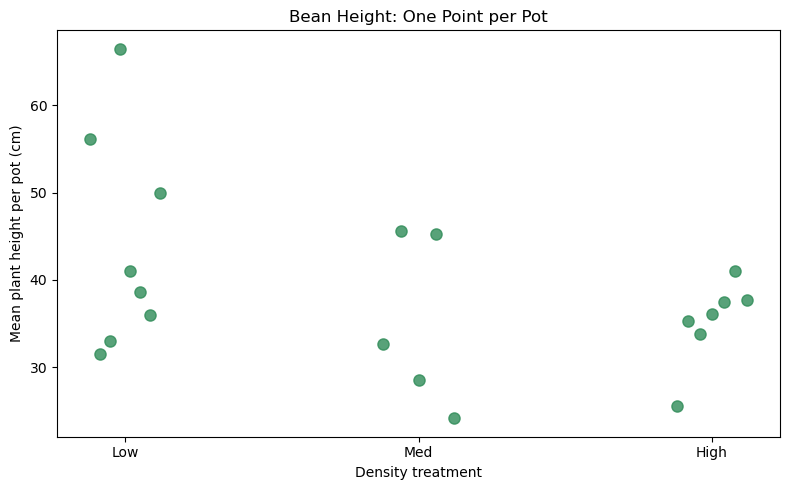

In [6]:
# Compare bean height across independent pots
fig, ax = plt.subplots(figsize=(8, 5))

densities = ["Low", "Med", "High"]

for position, density in enumerate(densities):
    pot_means = bean_pot_heights.loc[
        bean_pot_heights["Density"] == density,
        "Mean_height_cm"
    ].to_numpy()

    # Spread points horizontally to reduce overlap
    offsets = (
        np.linspace(-0.12, 0.12, len(pot_means))
        if len(pot_means) > 1
        else np.zeros(len(pot_means))
    )

    ax.scatter(
        position + offsets,
        pot_means,
        color="seagreen",
        s=65,
        alpha=0.8
    )

ax.set_xticks(range(3))
ax.set_xticklabels(densities)
ax.set_xlabel("Density treatment")
ax.set_ylabel("Mean plant height per pot (cm)")
ax.set_title("Bean Height: One Point per Pot")

plt.tight_layout()
plt.show()

## 🤔 Think

Each point represents one pot. Compare the points’ **vertical positions**.

- Are the pot means closely clustered or widely spread within each treatment?
- Does one treatment appear more variable than the others?
- How do the differences among treatments compare with the variation within treatments?

This graph helps us examine variation. It does not, by itself, establish that all assumptions hold.

## 📊 Worksheet — Experiment 4
Complete **Experiment 4: Choose a Statistical Test** on your worksheet (page 5). Explain your choice using the experimental design and variation among pots. 

💬 Compare your reasoning with your partner, then continue to Experiment 5.

## ➡️ Next Experiment

We’ve identified a method for comparing treatment means and considered the conditions it requires.

Next, we’ll select an appropriate version of ANOVA and evaluate the evidence that average bean height differs among density treatments.

<p align="center">
  <img src="Images/leaves.png" width="600">
</p>

# 🌱 Experiment 5: Testing for Differences

The graphs helped us explore the measurements. Now we’ll use a statistical test to evaluate the evidence for a density effect.

## 🤔 What Are We Testing?

Our question is:

**Does mean bean height differ among the three density treatments?**

A **one-way analysis of variance**, usually called a **one-way ANOVA**, compares the means of three or more groups.

“One-way” means that we are investigating one factor: **plant density**.

Our hypotheses are:

- **Null hypothesis:** Population mean bean height is the same under low, medium, and high density.
- **Alternative hypothesis:** At least one density treatment has a different population mean bean height.

The alternative does not require all three treatments to differ.

## ✍️ Before Running the Test
Complete **questions 1–2 in Experiment 5** on your worksheet (page 6): state the null and alternative hypotheses. Then run the ANOVA below.

<p align="center">
  <img src="Images/leaves.png" width="600">
</p>

## 💻 Run the ANOVA

Plants sharing a pot experienced the density treatment together. Therefore, we’ll use **one mean height per pot** as each observation in our analysis.

⬇️ Run the code below before continuing.

In [8]:
from scipy.stats import f_oneway

low = bean_pot_heights.loc[
    bean_pot_heights["Density"] == "Low", "Mean_height_cm"
]

medium = bean_pot_heights.loc[
    bean_pot_heights["Density"] == "Med", "Mean_height_cm"
]

high = bean_pot_heights.loc[
    bean_pot_heights["Density"] == "High", "Mean_height_cm"
]

anova_result = f_oneway(low, medium, high)

print("One-way ANOVA: Bean Height")
print("=" * 35)
print(f"F statistic: {anova_result.statistic:.3f}")
print(f"p-value: {anova_result.pvalue:.4f}")

One-way ANOVA: Bean Height
F statistic: 2.003
p-value: 0.1656


## 👀 Understanding the Output

The **F statistic** compares differences among treatment means with variation among pots within treatments. Larger F values indicate greater separation of the treatment means relative to the variation within treatments.

The **p-value** tells us how unusual an F statistic this large or larger would be if the null hypothesis and the test’s assumptions were true.

For this activity, we’ll use a significance level of **0.05**, chosen before interpreting the results:

- **p < 0.05:** We have statistical evidence that at least one treatment mean differs.
- **p ≥ 0.05:** We do not have sufficient statistical evidence to conclude that the treatment means differ.

A nonsignificant result does **not** establish that density has no effect.

## 🤔 Think

- What p-value did you obtain?
- Does it fall below our significance level?
- What can you conclude about the effect of density on bean height?
- Does ANOVA alone tell you which treatments differ?

## 📊 Reflection

➡️ Record and interpret your ANOVA result in the Experiment 5 section of your worksheet.

💬 Compare your interpretation with your partner.


## 🔎 Which Treatments Differ?

A significant ANOVA result tells us that at least one treatment mean differs—but it does not tell us **which treatments differ**.

For that, we can use **Tukey’s test** to compare:

- Low versus medium density
- Low versus high density
- Medium versus high density

Making several comparisons creates more opportunities to find an apparent difference by chance. Tukey’s test accounts for these multiple comparisons.

For this activity, we’ll use Tukey’s test as a follow-up **if our ANOVA result is statistically significant**.

## 💻 Check for Treatment Differences

The code below checks the ANOVA p-value. It runs Tukey’s test if the p-value is below 0.05; otherwise, it explains why we’re moving on.

⬇️ Run the code below before continuing.

In [9]:
if anova_result.pvalue < 0.05:
    from scipy.stats import tukey_hsd

    tukey_result = tukey_hsd(low, medium, high)

    treatment_names = ["Low", "Med", "High"]
    comparisons = []

    for i, j in [(0, 1), (0, 2), (1, 2)]:
        adjusted_p = tukey_result.pvalue[i, j]

        comparisons.append({
            "Comparison": (
                f"{treatment_names[i]} vs {treatment_names[j]}"
            ),
            "Adjusted p-value": f"{adjusted_p:.3g}",
            "Significant difference?": (
                "Yes" if adjusted_p < 0.05 else "No"
            )
        })

    print("Tukey's Test: Bean Height")
    display(pd.DataFrame(comparisons))

else:
    print("The ANOVA p-value is not below 0.05.")
    print("For this activity, we will not run follow-up comparisons.")
    print("We can still graph and describe the observed patterns!")

The ANOVA p-value is not below 0.05.
For this activity, we will not run follow-up comparisons.
We can still graph and describe the observed patterns!


## 👀 Interpret Your Result

**If Tukey’s test produced a table:**

The **adjusted p-values** account for the multiple comparisons. A value below 0.05 indicates statistical evidence of a difference between that pair of treatments.

Use your descriptive statistics to determine which treatment had the higher mean.

**If Tukey’s test did not run:**

Record that the ANOVA did not provide sufficient evidence of a difference among treatment means. Follow-up comparisons were not performed.

## 📊 Worksheet — Experiment 5
Complete **questions 3–6 in Experiment 5** on your worksheet (page 6). Record and interpret the bean-height ANOVA, explain whether Tukey comparisons were performed, and compare interpretations with your partner. Then continue to Experiment 6.

## ➡️ Next: Communicating Our Findings

Statistical tests help us evaluate evidence. A clear graph helps us communicate the results.

Next, we’ll create a figure showing the treatment means and the variation among pots.

<p align="center">
  <img src="Images/leaves.png" width="600">
</p>

# 🌱 Experiment 6: Communicating the Results

A useful scientific figure shows both the overall pattern and the variation in the data.

Our figure will include:

- **Green dots:** Mean height of the plants measured in each pot.
- **Black circles:** Average of the pot means within each density treatment.
- **Error bars:** One standard deviation above and below each treatment mean.

The standard deviation describes how much the pot means vary within a treatment.

Each pot contributes equally to the treatment mean, even when different numbers of plants were measured in different pots.

## 💻 Create the Figure

⬇️ Run the code below before continuing.

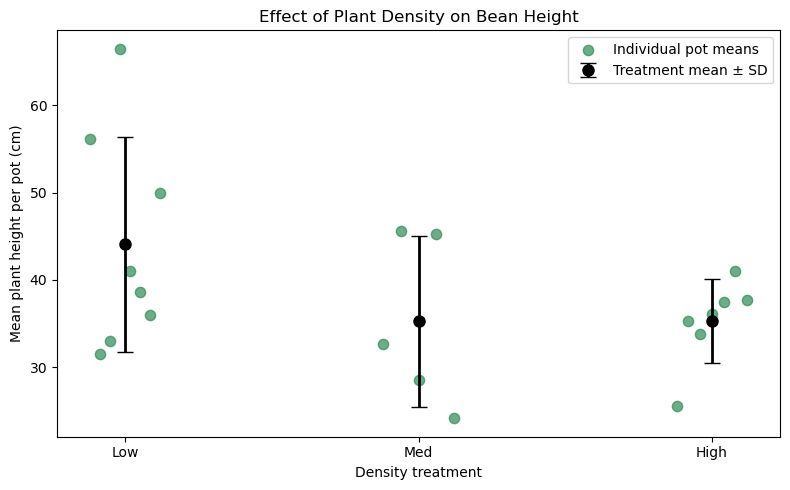

In [10]:
densities = ["Low", "Med", "High"]

height_summary = (
    bean_pot_heights.groupby("Density")["Mean_height_cm"]
    .agg(["mean", "std", "count"])
    .reindex(densities)
)

fig, ax = plt.subplots(figsize=(8, 5))

for position, density in enumerate(densities):
    pot_means = bean_pot_heights.loc[
        bean_pot_heights["Density"] == density,
        "Mean_height_cm"
    ].to_numpy()

    offsets = np.linspace(-0.12, 0.12, len(pot_means))

    ax.scatter(
        position + offsets,
        pot_means,
        color="seagreen",
        alpha=0.7,
        s=55,
        label="Individual pot means" if position == 0 else None
    )

ax.errorbar(
    range(len(densities)),
    height_summary["mean"],
    yerr=height_summary["std"],
    fmt="o",
    color="black",
    markersize=8,
    capsize=6,
    linewidth=2,
    label="Treatment mean ± SD"
)

ax.set_xticks(range(len(densities)))
ax.set_xticklabels(densities)
ax.set_xlabel("Density treatment")
ax.set_ylabel("Mean plant height per pot (cm)")
ax.set_title("Effect of Plant Density on Bean Height")
ax.legend()

plt.tight_layout()

fig.savefig("bean_height_figure.png", dpi=300, bbox_inches="tight")

plt.show()

## 👀 Read the Figure

The green dots show the observations used in our ANOVA: **one mean per pot**. Their small horizontal offsets simply make overlapping points easier to see.

The black circles summarize the treatment means. The error bars describe variation among the pot means within each treatment.

**Error-bar overlap is not a substitute for a statistical test.** Use your ANOVA and any follow-up comparisons to evaluate evidence of treatment differences.

## 🤔 Think

- Which density treatment has the highest observed mean height?
- Which treatment shows the most variation among pots?
- How does the figure help explain your statistical result?

## 💾 Save Your Figure

The code saved a file called **bean_height_figure.png** in this notebook’s folder.

Run the cell below to display a link to the image. Open the link and save the image to your computer for your lab report.

In [11]:
from IPython.display import FileLink, display

display(FileLink("bean_height_figure.png"))

/drive/greenhouse/bean_height_figure.png

## ✍️ Give Your Figure a Caption

A scientific figure needs a caption explaining what was measured and what its symbols represent.

Use this caption with your saved figure:

**Figure 1.** Bean height under low, medium, and high plant density. Green dots represent the mean height of the plants measured in each pot. Black circles show the average of the pot means within each density treatment; error bars represent ±1 standard deviation among pot means.

## 📊 Reflection

➡️ Complete the figure section for Experiment 6 on your worksheet.

💬 Compare your interpretation with your partner.

## ➡️ Next: From Measurements to Tables

Next, we’ll organize our descriptive statistics and test results into tables that can be saved and used in a research paper.

## 📋 Create a Table for Your Paper

A figure makes patterns easier to see. A table lets readers look up the exact values.

We’ll create a formatted table here in JL and save it as an image that you can insert directly into your paper.

Our table will show:

- The number of independent pots in each density treatment.
- The average of the pot means.
- The standard deviation among pot means.

## 💻 Build and Format the Table

The code below uses the descriptive statistics we already calculated.

Notice that we keep the measurement units in the column headings. That makes the table easier to read without repeating the units in every cell.

⬇️ Run the code below before continuing.

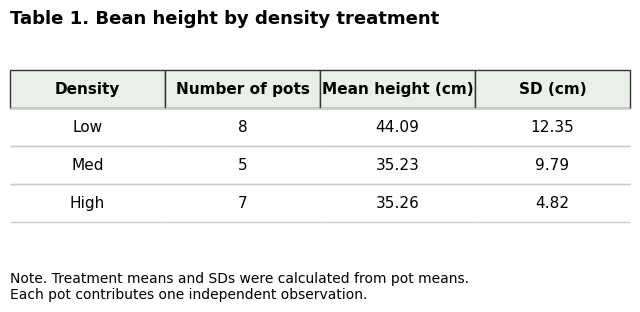

In [14]:
# Prepare the values for display.
table_rows = []

for density in densities:
    row = height_summary.loc[density]

    table_rows.append([
        density,
        f"{int(row['count'])}",
        f"{row['mean']:.2f}",
        f"{row['std']:.2f}"
    ])

# Create a figure to hold the table.
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.axis("off")

ax.set_title(
    "Table 1. Bean height by density treatment",
    loc="left",
    fontsize=13,
    fontweight="bold",
    pad=15
)

table = ax.table(
    cellText=table_rows,
    colLabels=[
        "Density",
        "Number of pots",
        "Mean height (cm)",
        "SD (cm)"
    ],
    cellLoc="center",
    bbox=[0, 0.30, 1, 0.60]
)

table.auto_set_font_size(False)
table.set_fontsize(11)

# Use horizontal rules and a shaded heading.
for (row, column), cell in table.get_celld().items():
    cell.visible_edges = "horizontal"
    cell.set_edgecolor("#cccccc")

    if row == 0:
        cell.set_facecolor("#e8f0e8")
        cell.set_text_props(weight="bold")
        cell.set_edgecolor("#333333")
        cell.visible_edges = "closed"

fig.text(
    0.125, 0.10,
    "Note. Treatment means and SDs were calculated from pot means.\n"
    "Each pot contributes one independent observation.",
    fontsize=10,
    va="bottom"
)

fig.savefig(
    "bean_height_table.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 👀 Check the Finished Table

A table should make sense without requiring readers to search through your methods.

Check that this table includes:

- A descriptive title.
- Clearly labeled columns and measurement units.
- The number of independent replicates.
- A note explaining how the measurements were summarized.

The values are displayed to two decimal places to keep the table readable. The statistical analyses still use the unrounded measurements.

## 💾 Save Your Finished Table

Run the cell below to display a link to the table image. Open the link and save the image to your computer.

You can insert this image directly into your paper.

In [15]:
from IPython.display import FileLink, display

display(FileLink("bean_height_table.png"))

/drive/greenhouse/bean_height_table.png

## 📊 Worksheet — Figure and Table
Complete **questions 1–2 in Experiment 6** on your worksheet (page 7). Explain the graph symbols and what makes the table understandable. Then begin the stem-diameter activity below.

## 💻 Your Turn: Make a Formatting Choice

Scientific tables should be readable and consistent throughout a paper.

In the table code above, find:

```python
fontsize=13
```

This controls the title size. Try changing it to `15`, then rerun the cell.

Which size is easier to read?

Choose the version you prefer, rerun the cell, and save the finished table again.

## ➡️ Apply the Workflow to Another Measurement

You have now explored, analyzed, graphed, and summarized bean height.

Next, you’ll adapt the analysis to investigate a different response: **stem diameter**.

The experimental question stays the same:

**Does plant density affect this measurement?**

## 💻 Your Turn: Investigate Stem Diameter

We used bean height to work through the analysis together. Now you’ll investigate another measurement.

**Does mean bean stem diameter differ among density treatments?**

The independent variable is still density. The dependent variable is now stem diameter.

Before running the analysis, make a prediction:

**Would you expect plants grown at higher density to have thicker or thinner stems? Why?**

## 📊 Worksheet — Stem Diameter
Complete **questions 4–5 in Experiment 6** on your worksheet (page 7). Describe the pattern and statistical evidence, then compare your interpretation with your partner. Return here to assemble the complete bean tables and generate the radish results.

<p align="center">
  <img src="Images/leaves.png" width="600">
</p>

## 💻 Your Turn: Investigate Stem Diameter

We used bean height to work through the analysis together. Now you’ll investigate another measurement.

**Does mean bean stem diameter differ among density treatments?**

The independent variable is still density. The dependent variable is now stem diameter.

Before running the analysis, make a prediction:

**Would you expect plants grown at higher density to have thicker or thinner stems? Why?**

### Step 1: Select the Measurement

The code below currently selects height.

Change:

```python
metric = "Height"
```

to:

```python
metric = "Stem"
```

Keep the quotation marks and the capital letter.

Then run the cell.

In [19]:
# Change the measurement selected here.
metric = "Stem"

# Select the bean measurements.
selected_data = df[
    (df["Species"] == "Bean") &
    (df["Metric"] == metric)
].copy()

# Calculate one mean per pot.
selected_pots = (
    selected_data.groupby(["Density", "Pot ID"], as_index=False)
    .agg(Pot_mean=("Value", "mean"))
)

# Summarize the pot means within each treatment.
selected_summary = (
    selected_pots.groupby("Density")["Pot_mean"]
    .agg(["count", "mean", "std"])
    .reindex(["Low", "Med", "High"])
)

measurement_labels = {
    "Height": "Height (cm)",
    "Stem": "Stem diameter (mm)",
    "Leaves": "Number of leaves"
}

print(f"Bean {measurement_labels[metric].lower()}")
print("Summary calculated from pot means:")

display(
    selected_summary.rename(columns={
        "count": "Number of pots",
        "mean": "Mean",
        "std": "SD"
    }).round(2)
)

Bean stem diameter (mm)
Summary calculated from pot means:


,Number of pots,Mean,SD
Density,,,
Low,8,5.30,2.92
Med,5,3.31,2.15
High,7,3.85,2.28


### Step 2: Run the Statistical Test

Before continuing, check the heading above your summary table.

**Does it say “Bean stem diameter (mm)”?**

If it still says height, change the measurement in Step 1 and rerun that cell.

The code below uses the measurement you selected. It runs a one-way ANOVA and, if the result is significant, Tukey’s follow-up comparisons.

⬇️ Run the code below before continuing.

In [20]:
selected_groups = [
    selected_pots.loc[
        selected_pots["Density"] == density, "Pot_mean"
    ].to_numpy()
    for density in ["Low", "Med", "High"]
]

selected_anova = f_oneway(*selected_groups)

print(f"One-way ANOVA: Bean {measurement_labels[metric].lower()}")
print(f"F statistic: {selected_anova.statistic:.3f}")
print(f"p-value: {selected_anova.pvalue:.4g}")

if selected_anova.pvalue < 0.05:
    from scipy.stats import tukey_hsd

    selected_tukey = tukey_hsd(*selected_groups)
    treatment_names = ["Low", "Med", "High"]
    comparison_rows = []

    for i, j in [(0, 1), (0, 2), (1, 2)]:
        p = selected_tukey.pvalue[i, j]

        comparison_rows.append({
            "Comparison": (
                f"{treatment_names[i]} vs {treatment_names[j]}"
            ),
            "Adjusted p-value": f"{p:.3g}",
            "Significant difference?": "Yes" if p < 0.05 else "No"
        })

    print("\nTukey's follow-up comparisons:")
    display(pd.DataFrame(comparison_rows))

else:
    print("\nNo follow-up comparisons were performed.")

One-way ANOVA: Bean stem diameter (mm)
F statistic: 1.115
p-value: 0.3508

No follow-up comparisons were performed.


## 🤔 Interpret Your Findings

Use the descriptive statistics and statistical test together.

- Which density treatment had the highest observed mean stem diameter?
- Did the ANOVA provide evidence of a difference among treatment means?
- If Tukey’s test ran, which pairs differed?
- Did your findings support your prediction?

Remember: the treatment with the highest observed mean does not necessarily differ significantly from the others.

## 📊 Reflection

➡️ Complete the stem-diameter analysis section on your worksheet.

Write two or three sentences describing the pattern and the statistical evidence. Include the ANOVA p-value.

💬 Compare your interpretation with your partner.

## ➡️ Assemble Your Results

You have now applied the workflow to a second measurement.

Next, we’ll use the same steps to generate a complete set of formatted summary tables for bean height, stem diameter, and leaf number. These will give you the numerical results you need for your paper without repeating every code cell.

<p align="center">
  <img src="Images/leaves.png" width="600">
</p>

## 📋 Assemble the Results for Your Paper

We’ll now apply the same analysis to:

- Plant height
- Stem diameter
- Number of leaves

For each measurement, the code calculates one mean per pot, summarizes the treatments, and runs a one-way ANOVA. It runs Tukey’s follow-up comparisons only when the ANOVA p-value is below 0.05.

**Automation repeats our instructions; it does not decide whether an analysis is appropriate.** The considerations from Experiment 4 apply to each response variable.

The code will create formatted tables that you can save as images and insert directly into your paper.

### 💻 Step 1: Prepare the Table Formatting

This cell defines a reusable set of formatting instructions. Running it prepares the instructions; the tables will appear after Step 2.

⬇️ Run the code below before continuing.

In [28]:
def report_p(p):
    """Format a p-value without reporting a very small value as zero."""
    return "< 0.001" if p < 0.001 else f"{p:.4f}"


def make_report_table(data, title, note, filename):
    """Display a formatted table and save it as an image."""
    figure_height = 2.2 + 0.34 * len(data)

    fig, ax = plt.subplots(figsize=(11, figure_height))
    ax.axis("off")

    ax.set_title(
        title,
        loc="left",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    table = ax.table(
        cellText=data.values,
        colLabels=data.columns,
        cellLoc="center",
        bbox=[0, 0.25, 1, 0.65]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(10)

    for (row, column), cell in table.get_celld().items():
        cell.visible_edges = "horizontal"
        cell.set_edgecolor("#cccccc")

        if row == 0:
            cell.set_facecolor("#e8f0e8")
            cell.set_text_props(weight="bold")
            cell.set_edgecolor("#333333")
            cell.visible_edges = "closed"

    fig.text(0.125, 0.06, note, fontsize=10, va="bottom")

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    display(FileLink(filename))
    
print("✅ Formatting parameters loaded!")

✅ Formatting parameters loaded!


### 💻 Step 2: Analyze and Summarize All Three Measurements

This cell repeats the workflow you used for height and stem diameter. All calculations use unrounded values; rounding happens only when preparing the tables for display.

The **Pots** column reports independent replicates, rather than individual plants.

⬇️ Run the code below before continuing.

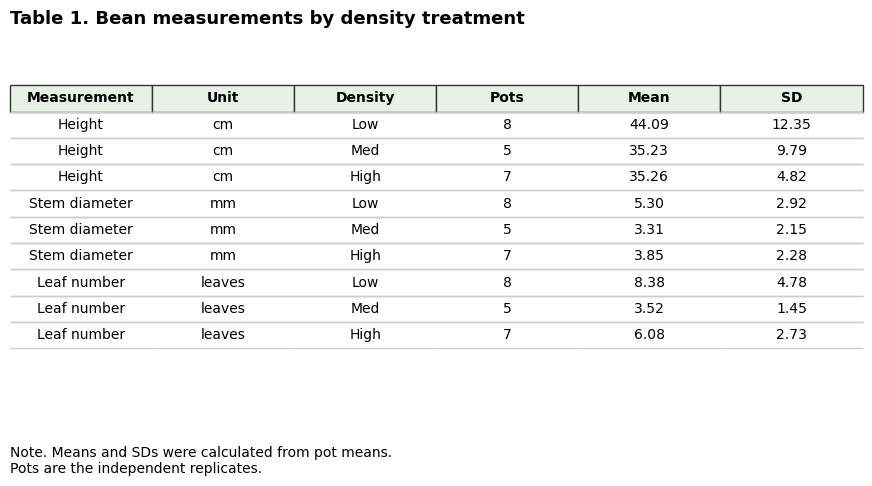

/drive/greenhouse/bean_descriptive_statistics_table.png

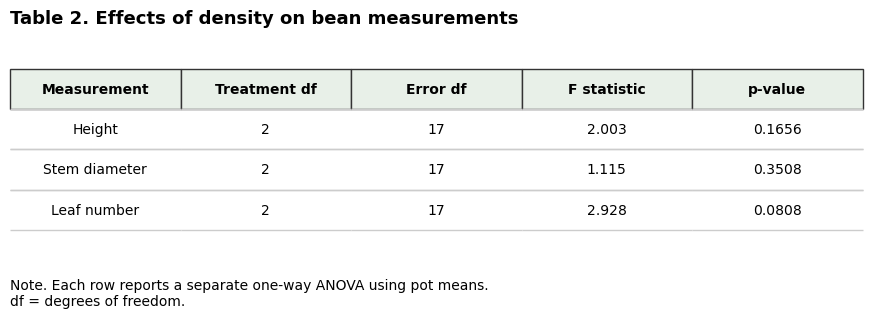

/drive/greenhouse/bean_anova_results_table.png

No ANOVA p-values were below 0.05.
A Tukey comparison table was therefore not generated.


In [22]:
from scipy.stats import f_oneway, tukey_hsd

measurements = [
    ("Height", "Height", "cm"),
    ("Stem", "Stem diameter", "mm"),
    ("Leaves", "Leaf number", "leaves")
]

density_order = ["Low", "Med", "High"]

descriptive_rows = []
anova_rows = []
tukey_rows = []

for metric_name, label, unit in measurements:

    # Select one measurement and calculate one mean per pot.
    measurements_for_trait = df[
        (df["Species"] == "Bean") &
        (df["Metric"] == metric_name)
    ]

    pots = (
        measurements_for_trait
        .groupby(["Density", "Pot ID"], as_index=False)
        .agg(Pot_mean=("Value", "mean"))
    )

    groups = [
        pots.loc[pots["Density"] == density, "Pot_mean"].to_numpy()
        for density in density_order
    ]

    # Prepare descriptive statistics.
    for density, values in zip(density_order, groups):
        descriptive_rows.append({
            "Measurement": label,
            "Unit": unit,
            "Density": density,
            "Pots": len(values),
            "Mean": f"{values.mean():.2f}",
            "SD": f"{values.std(ddof=1):.2f}"
        })

    # Run a separate ANOVA for this measurement.
    result = f_oneway(*groups)

    anova_rows.append({
        "Measurement": label,
        "Treatment df": len(groups) - 1,
        "Error df": sum(len(g) for g in groups) - len(groups),
        "F statistic": f"{result.statistic:.3f}",
        "p-value": report_p(result.pvalue)
    })

    # Run follow-up comparisons only after a significant ANOVA.
    if result.pvalue < 0.05:
        follow_up = tukey_hsd(*groups)

        for i, j in [(0, 1), (0, 2), (1, 2)]:
            p = follow_up.pvalue[i, j]

            tukey_rows.append({
                "Measurement": label,
                "Comparison": (
                    f"{density_order[i]} vs {density_order[j]}"
                ),
                "Adjusted p-value": report_p(p),
                "Significant difference?": (
                    "Yes" if p < 0.05 else "No"
                )
            })

# Display and save the descriptive table.
make_report_table(
    pd.DataFrame(descriptive_rows),
    "Table 1. Bean measurements by density treatment",
    "Note. Means and SDs were calculated from pot means.\n"
    "Pots are the independent replicates.",
    "bean_descriptive_statistics_table.png"
)

# Display and save the ANOVA table.
make_report_table(
    pd.DataFrame(anova_rows),
    "Table 2. Effects of density on bean measurements",
    "Note. Each row reports a separate one-way ANOVA using pot means.\n"
    "df = degrees of freedom.",
    "bean_anova_results_table.png"
)

# Display and save the Tukey table if applicable.
if tukey_rows:
    make_report_table(
        pd.DataFrame(tukey_rows),
        "Table 3. Tukey comparisons following significant ANOVAs",
        "Note. Comparisons are shown only for measurements with ANOVA p < 0.05.\n"
        "Tukey p-values account for the three comparisons within each measurement.",
        "bean_tukey_results_table.png"
    )
else:
    print("No ANOVA p-values were below 0.05.")
    print("A Tukey comparison table was therefore not generated.")

## 👀 Check Your Results

Before using the tables in your paper:

- Check that the height results agree with your earlier height analysis.
- Check that the stem-diameter results agree with your independent analysis.
- Identify the observed pattern for leaf number.
- Use the ANOVA table to distinguish observed differences from statistically significant differences.

We ran a separate ANOVA for each measurement. These p-values are not adjusted across the three response variables. Tukey’s adjustment applies to the density comparisons **within each measurement**.

## 💾 Save Your Finished Work

Save each table image using the links above.

The combined descriptive table replaces the height-only table we formatted earlier. Use the combined version in your paper rather than including both.

Also save:

- Your bean-height figure.
- A downloaded copy of your completed notebook.

Keep these files somewhere you can find them after closing JupyterLite.

<p align="center">
  <img src="Images/leaves.png" width="600">
</p>

# 🌱 Radish Results

We investigated the effect of density on beans and radishes as **separate experiments**.

The code below applies the same analysis to radishes:

- Calculate one mean per pot for each measurement.
- Summarize the three density treatments.
- Run a separate one-way ANOVA for each measurement.
- Run Tukey’s comparisons when an ANOVA is significant.
- Create formatted tables for your paper.

These analyses compare density treatments **within radishes**. They do not compare radishes with beans.

## 💻 Generate the Radish Tables

Run the table-formatting preparation cell earlier in this notebook before running this section.

The dataset must contain the reviewed radish measurements, with any agreed exclusions already applied. Root diameter is not included in this analysis.

⬇️ Run the code below before continuing.

In [29]:
def create_radish_reports(data):
    from scipy.stats import f_oneway, tukey_hsd

    # Select radishes without changing the original dataset.
    radish_data = data[
        data["Species"].astype(str).str.strip() == "Radish"
    ].copy()

    if radish_data.empty:
        print("🌱 No radish measurements are available in this dataset yet.")
        print("After loading the updated dataset, rerun this cell.")
        print("No radish tables were generated.")
        return

    measurements = [
        ("Height", "Height", "cm"),
        ("Stem", "Stem diameter", "mm"),
        ("Leaves", "Leaf number", "leaves")
    ]

    density_order = ["Low", "Med", "High"]

    descriptive_rows = []
    anova_rows = []
    tukey_rows = []

    for metric_name, label, unit in measurements:
        trait_data = radish_data[
            radish_data["Metric"] == metric_name
        ]

        if trait_data.empty:
            print(f"{label}: no measurements available; skipped.")
            continue

        # Calculate one mean per pot for this measurement.
        pots = (
            trait_data
            .groupby(["Density", "Pot ID"], as_index=False)
            .agg(Pot_mean=("Value", "mean"))
        )

        groups = [
            pots.loc[
                pots["Density"] == density, "Pot_mean"
            ].to_numpy()
            for density in density_order
        ]

        # Avoid producing incomplete three-treatment analyses.
        if any(len(group) < 2 for group in groups):
            counts = ", ".join(
                f"{density}: {len(group)} pots"
                for density, group in zip(density_order, groups)
            )
            print(f"{label}: skipped ({counts}).")
            print("At least two measured pots per treatment are required here.")
            continue

        for density, values in zip(density_order, groups):
            descriptive_rows.append({
                "Measurement": label,
                "Unit": unit,
                "Density": density,
                "Pots": len(values),
                "Mean": f"{values.mean():.2f}",
                "SD": f"{values.std(ddof=1):.2f}"
            })

        # ANOVA needs variation among pots within treatments.
        if all(group.var(ddof=1) == 0 for group in groups):
            print(f"{label}: no within-treatment variation.")
            print("Descriptive statistics retained; ANOVA not performed.")
            continue

        result = f_oneway(*groups)

        anova_rows.append({
            "Measurement": label,
            "Treatment df": len(groups) - 1,
            "Error df": sum(len(g) for g in groups) - len(groups),
            "F statistic": f"{result.statistic:.3f}",
            "p-value": report_p(result.pvalue)
        })

        if result.pvalue < 0.05:
            follow_up = tukey_hsd(*groups)

            for i, j in [(0, 1), (0, 2), (1, 2)]:
                p = follow_up.pvalue[i, j]

                tukey_rows.append({
                    "Measurement": label,
                    "Comparison": (
                        f"{density_order[i]} vs {density_order[j]}"
                    ),
                    "Adjusted p-value": report_p(p),
                    "Significant difference?": (
                        "Yes" if p < 0.05 else "No"
                    )
                })

    if descriptive_rows:
        make_report_table(
            pd.DataFrame(descriptive_rows),
            "Radish measurements by density treatment",
            "Note. Means and SDs were calculated from pot means.\n"
            "Pots are the independent replicates.",
            "radish_descriptive_statistics_table.png"
        )

    if anova_rows:
        make_report_table(
            pd.DataFrame(anova_rows),
            "Effects of density on radish measurements",
            "Note. Each row reports a separate one-way ANOVA using pot means.\n"
            "df = degrees of freedom.",
            "radish_anova_results_table.png"
        )

        if tukey_rows:
            make_report_table(
                pd.DataFrame(tukey_rows),
                "Radish Tukey comparisons following significant ANOVAs",
                "Note. Comparisons are shown only for measurements with ANOVA p < 0.05.\n"
                "Tukey p-values account for comparisons within each measurement.",
                "radish_tukey_results_table.png"
            )
        else:
            print("No radish ANOVA p-values were below 0.05.")
            print("A radish Tukey comparison table was not generated.")
    else:
        print("No radish ANOVA results were generated.")


create_radish_reports(df)

🌱 No radish measurements are available in this dataset yet.
After loading the updated dataset, rerun this cell.
No radish tables were generated.


## 👀 Review and Save

Check the messages above for any measurements that could not be analyzed. A missing result does not mean “no effect”—it means that analysis was not performed.

For the available results:

- Identify the observed patterns in the descriptive table.
- Interpret the ANOVA results.
- Report Tukey comparisons where applicable.
- Save the table images using their links.

As with beans, each ANOVA evaluates one response variable separately. Tukey’s adjustment applies to density comparisons within that response variable.

When assembling your paper, number all tables consecutively in the order you first mention them.

## ✍️ Connect the Two Experiments

Discuss the bean and radish findings separately before considering their biological implications.

You may describe whether the observed patterns look similar or different, but these analyses do not test whether the two species respond differently to density.

## ✍️ Bring the Evidence Together

For each measurement, your Results section should communicate:

1. The main observed pattern, supported by means and variation.
2. The ANOVA result.
3. Any significant Tukey comparisons, if performed.

Include nonsignificant findings. They are part of the experiment’s results.

Your Discussion can then consider possible biological explanations, limitations of the experiment, and questions for a future investigation.

# 🌱 Bring the Patterns Together

We’ll create one figure for beans and one for radishes. Each figure contains three panels showing different responses to density.

In every panel:

- Green dots represent individual pot means.
- Black circles represent treatment means.
- Error bars show ±1 standard deviation among pot means.
- The labels below each treatment show the number of measured pots.

Each panel has its own vertical scale and measurement units. Compare density treatments **within a panel**; the vertical positions across different measurements are not directly comparable.

## 💻 Prepare the Figures

Run this cell to prepare the plotting instructions. The following cell will create and save the figures.

In [31]:
def create_species_figure(data, species):
    species_data = data[
        data["Species"].astype(str).str.strip() == species
    ].copy()

    if species_data.empty:
        print(f"🌱 No {species.lower()} data are available yet.")
        print("Load the updated dataset and rerun the figure cell.")
        return

    measurements = [
        ("Height", "A", "Height", "Height (cm)"),
        ("Stem", "B", "Stem diameter", "Stem diameter (mm)"),
        ("Leaves", "C", "Leaf number", "Number of leaves")
    ]

    density_order = ["Low", "Med", "High"]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))
    any_data = False

    for ax, (metric, letter, title, ylabel) in zip(
        axes, measurements
    ):
        trait_data = species_data[
            species_data["Metric"] == metric
        ]

        pots = (
            trait_data
            .groupby(["Density", "Pot ID"], as_index=False)
            .agg(Pot_mean=("Value", "mean"))
        )

        if pots.empty:
            ax.set_title(f"{letter}  {title}", loc="left")
            ax.text(
                0.5, 0.5, "No measurements available",
                ha="center", va="center",
                transform=ax.transAxes
            )
            ax.set_axis_off()
            continue

        any_data = True
        tick_labels = []

        for position, density in enumerate(density_order):
            values = pots.loc[
                pots["Density"] == density, "Pot_mean"
            ].to_numpy()

            tick_labels.append(f"{density}\nn = {len(values)}")

            if len(values) == 0:
                continue

            offsets = (
                np.linspace(-0.12, 0.12, len(values))
                if len(values) > 1
                else np.zeros(1)
            )

            ax.scatter(
                position + offsets, values,
                color="seagreen",
                s=40, alpha=0.65, zorder=2
            )

            # A mean is available for one pot; SD requires two.
            if len(values) > 1:
                ax.errorbar(
                    position, values.mean(),
                    yerr=values.std(ddof=1),
                    fmt="o", color="black",
                    markersize=7, capsize=5,
                    linewidth=1.8, zorder=3
                )
            else:
                ax.plot(
                    position, values.mean(),
                    "o", color="black",
                    markersize=7, zorder=3
                )

        ax.set_title(
            f"{letter}  {title}",
            loc="left", fontsize=12, fontweight="bold"
        )
        ax.set_xticks(range(3))
        ax.set_xticklabels(tick_labels)
        ax.set_xlim(-0.45, 2.45)
        ax.set_xlabel("Density treatment")
        ax.set_ylabel(ylabel)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    if not any_data:
        plt.close(fig)
        print(f"No supported measurements found for {species.lower()}s.")
        return

    fig.suptitle(
        f"Plant Density and {species} Growth",
        fontsize=16, fontweight="bold"
    )

    fig.text(
        0.5, 0.04,
        "Green dots: individual pot means    "
        "Black circles and bars: treatment mean ± SD",
        ha="center", fontsize=10
    )

    fig.tight_layout(rect=[0, 0.10, 1, 0.91])

    filename = f"{species.lower()}_growth_figure.png"

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    display(FileLink(filename))


print("✅ Figure instructions loaded!")

✅ Figure instructions loaded!


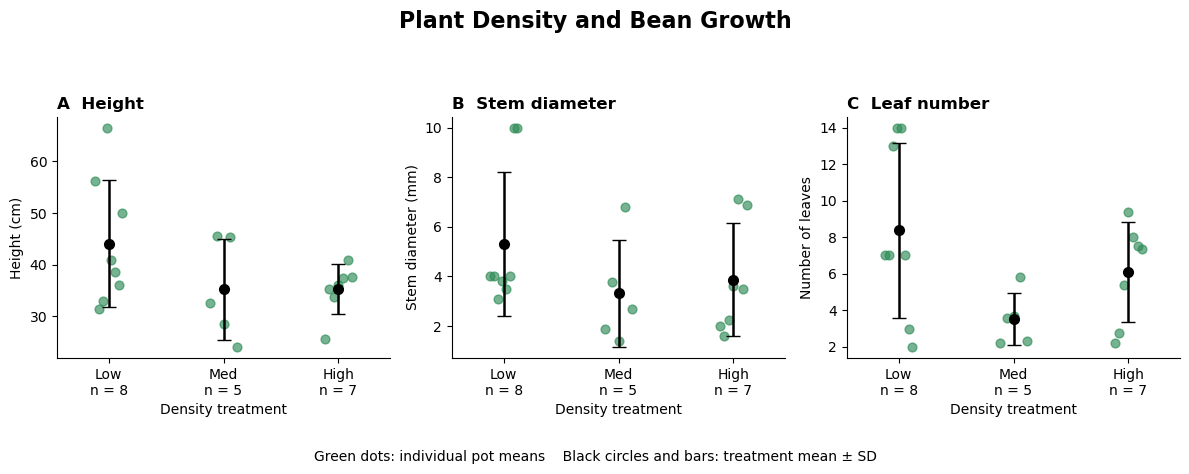

/drive/greenhouse/bean_growth_figure.png

🌱 No radish data are available yet.
Load the updated dataset and rerun the figure cell.


In [32]:
create_species_figure(df, "Bean")
create_species_figure(df, "Radish")

## 💾 Save the Combined Figures

Save each figure using the link below it.

Use the combined bean figure in your paper instead of including both it and the earlier bean-height figure.

If radish measurements are not available yet, the code will display a message. Rerun the cell after loading the updated dataset.

## ✍️ Figure Captions

Number the figures in the order you first mention them in your paper. Use these captions, adding the appropriate figure numbers.

**Beans.** Effect of planting density on bean height (A), stem diameter (B), and leaf number (C). Green dots represent individual pot means. Black circles show treatment means; error bars represent ±1 standard deviation among pot means. Sample sizes indicate the number of pots with measurements for each response and treatment. Panels use different vertical scales and units.

**Radishes.** Effect of planting density on radish height (A), stem diameter (B), and leaf number (C). Green dots represent individual pot means. Black circles show treatment means; error bars represent ±1 standard deviation among pot means. Sample sizes indicate the number of pots with measurements for each response and treatment. Panels use different vertical scales and units.

Interpret the patterns using the statistical tables. Error-bar overlap alone does not determine statistical significance.

## 📊 Worksheet — Radish Results
Complete the **radish results table** on your worksheet (page 8). Treat radishes as a separate density experiment. If a result is unavailable, record that the analysis was not performed rather than interpreting it as no effect.

<p align="center">
  <img src="Images/leaves.png" width="600">
</p>

## 📊 Worksheet — Final Reflection
Complete **Final Reflection** on your worksheet (page 8). Discuss beans and radishes separately, support your conclusions with evidence, and identify what remains uncertain. Compare conclusions with your partner, then check that you have saved your figures, tables, and a downloaded notebook.

<p align="center">
  <img src="Images/leaves.png" width="600">
</p>